# Validation tests

In [ ]:
#libraries
import QuantLib as ql
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad

## SciPy Implementation

In [ ]:
def heston_charac_function(
        u,
        S0,
        T,
        r,
        v0,
        kappa,
        theta,
        sigma,
        rho
):
    i = 1j
    d = np.sqrt(
        (rho*sigma*i*u-kappa)**2
        + sigma**2 * (i * u + u**2)
    )
    g = (
        kappa - rho * sigma * i * u - d
    )/(
        kappa - rho * sigma * i * u + d
    )
    C = (
        r * i * u * T
        + (kappa * theta / sigma**2)
        *(
            (kappa - rho * sigma * i * u - d) * T
            - 2
            * np.log(
                (1-g * np.exp(-d*T))
                / (1-g)
            )
        )
    )
    D = (
        (kappa - rho * sigma * i * u - d)
        / sigma ** 2
        * (
            (1 - np.exp(-d * T))
            / (1 - g * np.exp(-d * T))
        )
    )
    return np.exp(
        C
        + D * v0
        + i * u * np.log(S0)
    )

def heston_probability(
        j,
        S0,
        K,
        T,
        r,
        v0,
        kappa,
        theta,
        sigma,
        rho
):
    phi_minus_i = heston_charac_function(
        -1j,
        S0,
        T,
        r,
        v0,
        kappa,
        theta,
        sigma,
        rho
    )
    def integrand(u):
        phi_u = heston_charac_function(
            u,
            S0,
            T,
            r,
            v0,
            kappa,
            theta,
            sigma,
            rho
        )
        if j == 1:
            phi_shifted = heston_charac_function(
                u-1j,
                S0,
                T,
                r,
                v0,
                kappa,
                theta,
                sigma,
                rho
            )
            value = (
                np.exp(-1j * u * np.log(K))
                * phi_shifted
                / (1j * u * phi_minus_i)
            )
        else:
            value = (
                np.exp(-1j * u * np.log(K))
                * phi_u
                /(1j * u)
            )
        return np.real(value)
    integral, error = quad(
        integrand,
        1e-8,
        100,
        limit=500
    )
    return 0.5 + integral/np.pi

def heston_price_scipy(
        S0,
        K,
        T,
        r,
        v0,
        kappa,
        theta,
        sigma,
        rho
):
    P1 = heston_probability(
        1,
        S0,
        K,
        T,
        r,
        v0,
        kappa,
        theta,
        sigma,
        rho
    )

    P2 = heston_probability(
        2,
        S0,
        K,
        T,
        r,
        v0,
        kappa,
        theta,
        sigma,
        rho
    )

    price = (
        S0 * P1 - K * np.exp(-r * T) * P2
    )

    return price

## QuantLib Implementation

In [ ]:
#reusing quantlib function from before
def heston_quantlib_prices(
    S0, #stock price today
    K, #strike price
    T, #time to maturity (in years)
    r, #risk free interest rate
    v0, #variance today
    kappa, #speed of mean reversion
    theta, #long run variance
    sigma, #volatility of variance
    rho, #correlation between stock and variance
    q=0.0 #dividend yield
):
    #date setup
    today = ql.Date.todaysDate()
    ql.Settings.instance().evaluationDate = today

    #conversion of T into maturity date
    maturity_date = today + int(round(T * 365))

    #day count conversion
    day_count = ql.Actual365Fixed()

    #spot price
    spot = ql.QuoteHandle(
        ql.SimpleQuote(S0)
    )

    #risk free rate
    risk_free_curve = ql.YieldTermStructureHandle(
        ql.FlatForward(today,r,day_count)
    )

    dividend_curve = ql.YieldTermStructureHandle(
        ql.FlatForward(today,q,day_count)
    )

    heston_process = ql.HestonProcess(
        risk_free_curve,
        dividend_curve,
        spot,
        v0,
        kappa,
        theta,
        sigma,
        rho
    )

    #heston model
    heston_model = ql.HestonModel(heston_process)

    #analytical heston pricing engine
    engine = ql.AnalyticHestonEngine(heston_model)

    #European call
    payoff = ql.PlainVanillaPayoff(
        ql.Option.Call,
        K
    )

    #
    exercise = ql.EuropeanExercise(
        maturity_date
    )

    option = ql.VanillaOption(
        payoff,
        exercise
    )

    option.setPricingEngine(engine)

    return option.NPV()

## Validation Test 1:
Reproducing result from known example

In [ ]:
params = {
    "S0": 100.0,
    "K": 100.0,
    "T": 1.0,
    "r": 0.03,
    "v0": 0.04,
    "kappa": 2.0,
    "theta": 0.04,
    "sigma": 0.30,
    "rho": -0.70
}

ql_price = heston_quantlib_prices(**params)
scipy_price = heston_price_scipy(**params)
print(f"QuantLib price: {ql_price:.8f}")
print(f"Scipy Price: {scipy_price: .10f}")

QuantLib price: 9.24252107
Scipy Price:  9.2425210615


In [ ]:
absolute_error = abs(
    ql_price - scipy_price
)

relative_error = (
    absolute_error / abs(ql_price)
)

print(f"Absolute error: {absolute_error: .10e}")
print(f"Relative error: {relative_error: .10e}")

Absolute error:  1.2464379751e-08
Relative error:  1.3485908932e-09


In [ ]:
print(f"Relative Error: {relative_error * 100: .8f}%")

Relative Error:  0.00000013%


In [ ]:
def compare_pricers(params):
    ql_price = heston_quantlib_prices(**params)
    scipy_price = heston_price_scipy(**params)
    abs_error = abs(ql_price - scipy_price)
    rel_error = (abs_error / max(abs(ql_price), 1e-12))
    return{
        **params,
        "quantlib_price": ql_price,
        "scipy_price": scipy_price,
        "absolute_error": abs_error,
        "relative_error": rel_error
    }

result = compare_pricers(params)
result

{'S0': 100.0,
 'K': 100.0,
 'T': 1.0,
 'r': 0.03,
 'v0': 0.04,
 'kappa': 2.0,
 'theta': 0.04,
 'sigma': 0.3,
 'rho': -0.7,
 'quantlib_price': 9.242521073959065,
 'scipy_price': 9.242521061494685,
 'absolute_error': 1.2464379750554144e-08,
 'relative_error': 1.3485908932004183e-09}

In [ ]:
strikes = np.arange(60,141, 10)
results = []

for K in strikes:
    test_params = {
        "S0": 100.0,
        "K": float(K),
        "T": 1.0,
        "r": 0.03,
        "v0": 0.04,
        "kappa": 2.0,
        "theta": 0.04,
        "sigma": 0.30,
        "rho": -0.70
    }
    result = compare_pricers(test_params)

    results.append(result)

In [ ]:
df_strikes = pd.DataFrame(results)
df_strikes

,S0,K,T,r,v0,kappa,theta,sigma,rho,quantlib_price,scipy_price,absolute_error,relative_error
0,100.0,60.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,41.917039,41.917039,8.162269e-08,1.947244e-09
1,100.0,70.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,32.552145,32.552145,4.980281e-08,1.529940e-09
2,100.0,80.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,23.689771,23.689771,2.896944e-08,1.222867e-09
3,100.0,90.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,15.750434,15.750434,1.702191e-08,1.080727e-09
4,100.0,100.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,9.242521,9.242521,1.246438e-08,1.348591e-09
5,100.0,110.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,4.583971,4.583971,1.420450e-08,3.098733e-09
6,100.0,120.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,1.838020,1.838020,2.139393e-08,1.163966e-08
7,100.0,130.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,0.581334,0.581334,3.338569e-08,5.742946e-08
8,100.0,140.0,1.0,0.03,0.04,2.0,0.04,0.3,-0.7,0.147991,0.147991,4.964187e-08,3.354392e-07


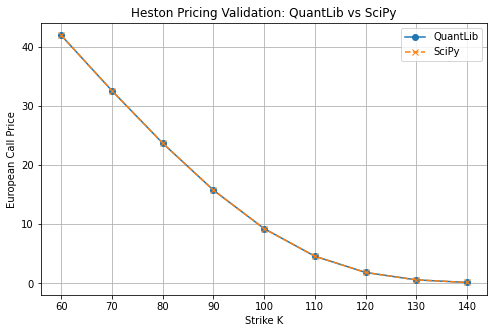

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_strikes["K"].to_numpy(),
    df_strikes["quantlib_price"].to_numpy(),
    marker="o",
    label="QuantLib"
)

plt.plot(
    df_strikes["K"].to_numpy(),
    df_strikes["scipy_price"].to_numpy(),
    marker="x",
    linestyle="--",
    label="SciPy"
)

plt.xlabel("Strike K")
plt.ylabel("European Call Price")
plt.title("Heston Pricing Validation: QuantLib vs SciPy")

plt.legend()
plt.grid(True)

plt.show()

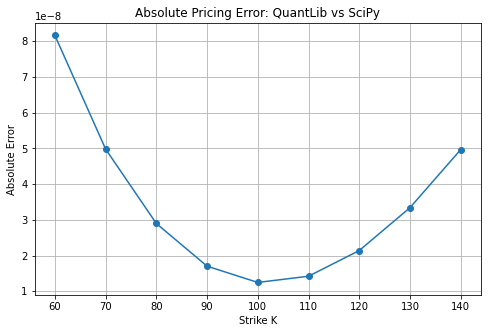

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    df_strikes["K"].to_numpy(),
    df_strikes["absolute_error"].to_numpy(),
    marker="o"
)

plt.xlabel("Strike K")
plt.ylabel("Absolute Error")
plt.title("Absolute Pricing Error: QuantLib vs SciPy")

plt.grid(True)
plt.show()

In [ ]:
#testing different maturities
maturities = [
    0.1,
    0.25,
    0.5,
    1.0,
    2.0,
    3.0,
    5.0
]

results = []

for T in maturities:
    test_params = {
        "S0": 100.0,
        "K": 100.0,
        "T": T,
        "r": 0.03,
        "v0": 0.04,
        "kappa": 2.0,
        "theta": 0.04,
        "sigma": 0.30,
        "rho": -0.70
    }
    results.append(compare_pricers(test_params))

df_maturities = pd.DataFrame(results)

df_maturities[
    [
        "T",
        "quantlib_price",
        "scipy_price",
        "absolute_error",
        "relative_error"
    ]
]

,T,quantlib_price,scipy_price,absolute_error,relative_error
0,0.10,2.637091,2.656158,1.906712e-02,7.230362e-03
1,0.25,4.300682,4.306981,6.298921e-03,1.464633e-03
2,0.50,6.255251,6.264681,9.429731e-03,1.507490e-03
3,1.00,9.242521,9.242521,1.246438e-08,1.348591e-09
4,2.00,13.890648,13.890648,2.489610e-08,1.792293e-09
5,3.00,17.751819,17.751819,3.747766e-08,2.111201e-09
6,5.00,24.256979,24.256979,6.312662e-08,2.602411e-09


In [ ]:
#random heston params
rng = np.random.default_rng(42)
n_test = 100

results = []

for _ in range(n_test):
    test_params = {
        "S0": 100.0,
        "K": rng.uniform(70,130),
        "T": rng.uniform(0.1, 3.0),
        "r": rng.uniform(0.0,0.08),
        "v0": rng.uniform(0.01, 0.16),
        "kappa": rng.uniform(0.5, 5.0),
        "theta": rng.uniform(0.01, 0.16),
        "sigma": rng.uniform(0.1, 1.0),
        "rho": rng.uniform(-0.9, -0.1)
    }

    try:
        result = compare_pricers(test_params)
        results.append(results)
    except Exception as e:
        print("Failed parameter set:")
        print(test_params)
        print(e)

In [ ]:
df_validation = pd.DataFrame(results)
df_validation.head()

KeyboardInterrupt: 

In [ ]:
print("Number of successful tests:", len(df_validation))
print("Mean absolute error:",
      df_validation["absolute_error"].mean())
print("Median absolute error:",
      df_validation["absolute_error"].median())
print("Max absolute error:",
      df_validation["absolute_error"].max())
print("Mean relative error:",
      df_validation["relative_error"].mean())
print("Median relative error:",
      df_validation["relative_error"].median())
print("Max relative error:",
      df_validation["relative_error"].max())

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df_validation["quantlib_price"],
    df_validation["scipy_price"],
    alpha=0.6
)

minimum = min(
    df_validation["quantlib_price"].min(),
    df_validation["scipy_price"].min()
)

maximum = max(
    df_validation["quantlib_price"].max(),
    df_validation["scipy_price"].max()
)

plt.plot(
    [minimum,minimum],
    [minimum,maximum],
    "--",
    label="Perfect Agreement"
)

plt.xlabel("Quantlib Heston Price")
plt.ylabel("SciPy Heston Price")

plt.title(
    "Validation of Heston Pricing Implementation"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
worst_index = (
    df_validation["absolute_error"].idxmax()
)

worst_case = df_validation.loc[worst_index]

worst_case

In [ ]:
#validation 2: basic no arbitrage bound
lower_bound = max(
    params["S0"] - params["K"] * np.exp(-params["r"] * params["T"]),
    0
)

upper_bound = params["S0"]

print(f"Lower bound: {lower_bound:.6f}")
print(f"Heston price: {ql_price: .6f}")
print(f"Upper bound: {upper_bound:.6f}")

assert lower_bound <= ql_price <= upper_bound

print("No-arbitrage bounds passed")

Lower bound: 2.955447
Heston price:  9.242521
Upper bound: 100.000000
No-arbitrage bounds passed


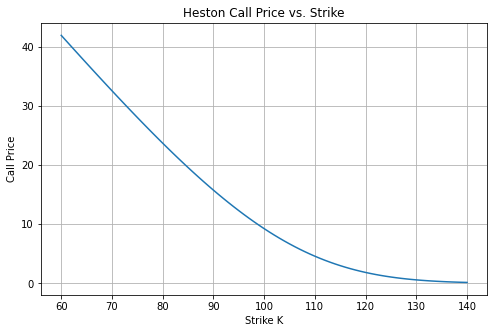

In [ ]:
#validation 3: price should decrease with strike

strikes = np.linspace(60, 140, 81)

prices = []

for K in strikes:
    price = heston_quantlib_prices(
        S0 = 100,
        K = K,
        T = 1.0,
        r = 0.03,
        v0 = 0.04,
        kappa = 2.0,
        theta = 0.04,
        sigma = 0.30,
        rho = -0.70
    )

    prices.append(price)


#plotting validation
plt.figure(figsize=(8, 5))
plt.plot(strikes, prices)
plt.xlabel("Strike K")
plt.ylabel("Call Price")
plt.title("Heston Call Price vs. Strike")

plt.grid(True)
plt.show()


In [ ]:
assert np.all(np.diff(prices) <= 1e-10)

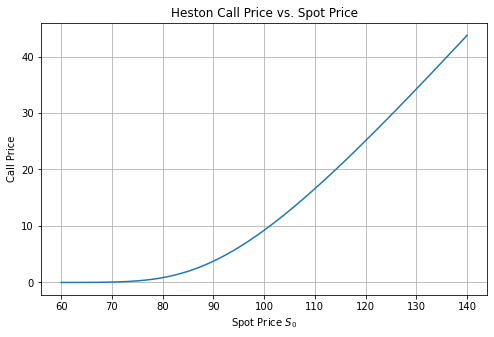

In [ ]:
#validation 4: price behaviour with spot
spots = np.linspace(60, 140, 81)

spot_prices = []

for S0 in spots:
    price = heston_quantlib_prices(
        S0=S0,
        K=100,
        T=1.0,
        r=0.03,
        v0=0.04,
        kappa=2.0,
        theta=0.04,
        sigma=0.30,
        rho=-0.70
    )
    spot_prices.append(price)

#plotting
plt.figure(figsize=(8,5))
plt.plot(spots,spot_prices)
plt.xlabel("Spot Price $S_0$")
plt.ylabel("Call Price")
plt.title("Heston Call Price vs. Spot Price")

plt.grid(True)
plt.show()


#test
assert np.all(np.diff(spot_prices)>=-1e-10)